In [1]:
#!pip install pandas
#!pip install matplotlib
#!pip install seaborn
#!pip install scikit-learn
#!pip install openpyxl --upgrade
#!pip install statsmodels

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
classification_report,confusion_matrix,roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score)

In [3]:
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

# Problema 1 – Regressão Linear para Previsão de Producão de Energia em uma Usina de Ciclo Combinado

## 1.1 Carregando os dados

In [4]:
ccpp = pd.read_excel('datasets/ccpp.xlsx')
ccpp.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [5]:
ccpp.info()

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


## 1.2 Correlação entre as variáveis

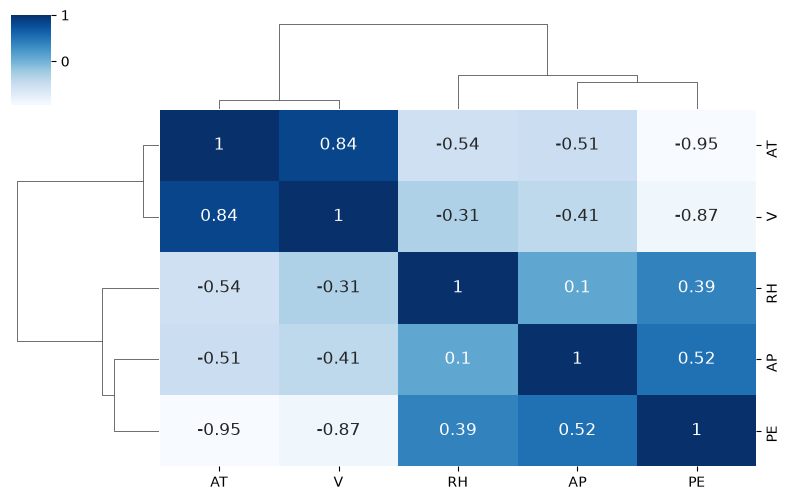

In [6]:
sns.clustermap(data = ccpp.corr(), cmap = 'Blues', annot = True, annot_kws = {'fontsize': 12}, figsize=(8, 5));

As variáveis `Vácuo de escape (V)`e `Temperatura ambiente (AT)` tem maior influência na variável `Pressão de Saída (PE)`. Além disso, `Vácuo de escape (V)`e `Temperatura ambiente (AT)` possuem alta correlação entre si, o que é um indicativo de multicolinearidade.

## 1.3 Construção do modelo

In [7]:
ccpp_train, ccpp_test = train_test_split(ccpp, test_size = 0.2, random_state = 7)
scaler = MinMaxScaler()
ccpp_train_scaled = scaler.fit_transform(ccpp_train)
ccpp_test_scaled = scaler.transform(ccpp_test)
ccpp_train_scaled = pd.DataFrame(ccpp_train_scaled, columns = ccpp_train.columns)
ccpp_test_scaled = pd.DataFrame(ccpp_test_scaled, columns = ccpp_test.columns)

In [8]:
import statsmodels.formula.api as smf

formula = "PE ~ AT + V + RH + AP"
LinReg =smf.ols(formula = formula, data = ccpp_train_scaled).fit()
LinReg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 2.498e+04
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:23:01   Log-Likelihood:                 10633.
No. Observations:                7654   AIC:                        -2.126e+04
Df Residuals:                    7649   BIC:                        -2.122e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.0943      0.007    168.044      0.000       1.081       1.107
AT            -0.9277      0.008   -116.544      0.000      -0.943      -0.912
V             -0.1727      0.006    -28.597      0.000      -0.185      -0.161
RH            -0.1560      0.005    -33.817      0.000      -0.165      -0.147
AP             0.0295      0.006      5.214      0.000       0.018       0.041
==============================================================================
Omnibus:                      739.123   Durbin-Watson:                   2.004
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3424.692
Skew:                          -0.367   Prob(JB):                         0.00
Kurtosis:                       6.193   Cond. No.                         24.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<Axes: xlabel='PE', ylabel='Predictions'>

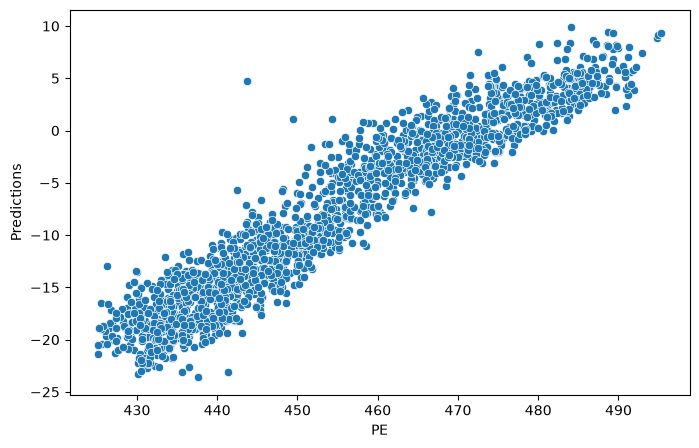

In [9]:
plt.plot(figsize = (8, 6))
predictions = LinReg.predict(ccpp_test)
ccpp_test['Predictions'] = predictions
sns.scatterplot(x = 'PE', y = 'Predictions', data = ccpp_test)

## 1.4 Avaliação do desempenho do modelo

In [10]:
from statsmodels.tools.eval_measures import rmse, meanabs

y = ccpp_test['PE']
y_pred = ccpp_test['Predictions']

r2 = LinReg.rsquared
rmse = rmse(y, y_pred)
mae = meanabs(y, y_pred)

print(f'R2: {r2:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mae:.2f}')


R2: 0.93
RMSE: 462.72
MAE: 462.62


# Problema 2 – Regressão Logística para Previsão de Doenças Cardíacas

## 2.1 Obtenção dos dados

In [11]:
cols = ['age', 'sex', 'cp', 'trestbps', 'chol',
       'fbs', 'restecg', 'thalach', 'exang', 'oldpeak',
       'slope', 'ca', 'thal', 'target']

cleveland_df = pd.read_csv('datasets/cleveland_data.csv', header = None, names = cols)
display(cleveland_df)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


In [12]:
cleveland_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    str    
 12  thal      303 non-null    str    
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), str(2)
memory usage: 33.3 KB


## 1.2 Pré-processamento dos dados
### 1.2.1 Padronização dos dados

In [13]:
sex_cat = cleveland_df['sex'].unique()
cp_cat = cleveland_df['cp'].unique()
restecg_cat = cleveland_df['restecg'].unique()
slope_cat = cleveland_df['slope'].unique()
ca_cat = cleveland_df['ca'].unique()
thal_cat = cleveland_df['thal'].unique()
target_cat = cleveland_df['target'].unique()

print(f'sex: {sex_cat}')
print(f'cp: {cp_cat}')
print(f'restecg: {restecg_cat}')
print(f'slope: {slope_cat}')
print(f'ca: {ca_cat}')
print(f'thal: {thal_cat}')
print(f'target: {target_cat}')

sex: [1. 0.]
cp: [1. 4. 3. 2.]
restecg: [2. 0. 1.]
slope: [3. 2. 1.]
ca: <StringArray>
['0.0', '3.0', '2.0', '1.0', '?']
Length: 5, dtype: str
thal: <StringArray>
['6.0', '3.0', '7.0', '?']
Length: 4, dtype: str
target: [0 2 1 3 4]


In [14]:
indices_to_drop = cleveland_df.query('ca == "?" or thal == "?"').index
cleveland_df.drop(indices_to_drop, inplace = True)

/tmp/ipykernel_10887/3683111289.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cleveland_df.drop(indices_to_drop, inplace = True)


In [15]:
cleveland_df = cleveland_df.astype({'ca': float, 'thal': float})

### 1.2.2 Binarização da variável alvo



In [16]:
cleveland_df['target'] = cleveland_df['target'].apply(lambda x: 1 if x > 0 else 0)

In [17]:
cleveland_df = cleveland_df.astype(int)

In [18]:
cleveland_df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

### 1.2.3 Normalização da variável independente


In [19]:
scaler = MinMaxScaler()

data = cleveland_df.drop('target', axis = 1)
cleveland_df_scaled = scaler.fit_transform(data)
cleveland_df_scaled = pd.DataFrame(cleveland_df_scaled, columns = data.columns)
cleveland_df_scaled['target'] = cleveland_df['target']
cleveland_df_scaled.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,0.708333,1.0,0.000000,0.481132,0.244292,1.0,1.0,0.603053,0.0,0.333333,1.0,0.000000,0.75,0.0
1,0.791667,1.0,1.000000,0.622642,0.365297,0.0,1.0,0.282443,1.0,0.166667,0.5,1.000000,0.00,1.0
2,0.791667,1.0,1.000000,0.245283,0.235160,0.0,1.0,0.442748,1.0,0.333333,0.5,0.666667,1.00,1.0
3,0.166667,1.0,0.666667,0.339623,0.283105,0.0,0.0,0.885496,0.0,0.500000,1.0,0.000000,0.00,0.0
4,0.250000,0.0,0.333333,0.339623,0.178082,0.0,1.0,0.770992,0.0,0.166667,0.0,0.000000,0.00,0.0


## 2.3 Treinamento do modelo

In [20]:
import patsy

cleveland_df_train, cleveland_df_test = train_test_split(cleveland_df, test_size = 0.2, random_state = 7)
formula = '''target ~ age + sex + C(cp) + trestbps +
chol + fbs + C(restecg) + thalach + exang +
oldpeak + C(slope) + ca + C(thal)'''

y_train, X_train = patsy.dmatrices(formula, data = cleveland_df_train, return_type = 'dataframe')

In [21]:
X_train_info = [X_train.design_info]
y_train_info = [y_train.design_info]

In [22]:
X_test = patsy.build_design_matrices(X_train_info, cleveland_df_test,
                                     return_type = 'dataframe')[0]
y_test = patsy.build_design_matrices(y_train_info, cleveland_df_test,
                                     return_type = 'dataframe')[0]

In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000, fit_intercept=False)
model.fit(X_train, np.ravel( y_train))

,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual

In [24]:
t0 = model.intercept_
t_values = np.round(model.coef_[0], decimals=2)

print(f't0 = {t0}')
print(f't_values = {t_values}')

t0 = 0.0
t_values = [-0.49  0.22 -0.41  1.04  0.08  0.47  0.71  0.55  0.06  1.6  -0.04  0.95
  0.02  0.01 -0.22 -0.03  0.44  0.39  1.33]


In [25]:
#número de iterações necessarias para a convergência do modelo
model.n_iter_.item()

13

## 2.4 Avaliação do modelo

In [26]:
y_pred =  model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

print(f'Acurácia: {accuracy_score(y_test, y_pred):.4f}')
print(f'Precisão: {precision_score(y_test, y_pred):.4f}')
print(f'Recall: {recall_score(y_test, y_pred):.4f}')
print(f'F1: {f1_score(y_test, y_pred):.4f}')

Acurácia: 0.8167
Precisão: 0.8400
Recall: 0.7500
F1: 0.7925


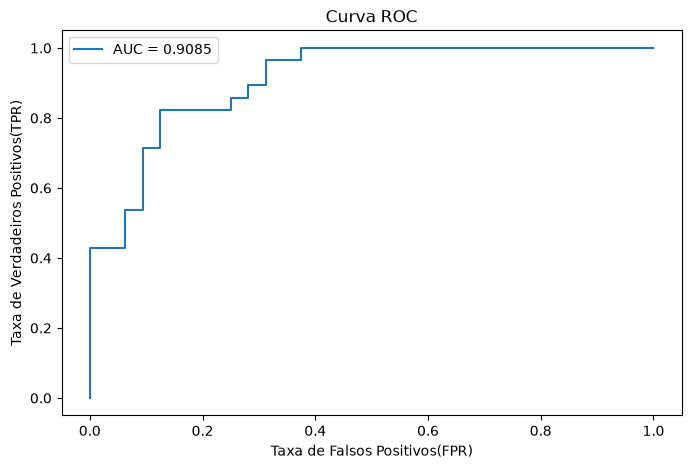

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
plt.xlabel('Taxa de Falsos Positivos(FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos(TPR)')
plt.title('Curva ROC')
plt.legend()
plt.show()

# Problema 3 – Classificacão de Qualidade de Vinhos Utilizando 𝑘-NN

## 3.1 Carregando o dataset

In [28]:
winequality_df = pd.read_csv('datasets/winequality-red.csv', sep = ';')
winequality_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [29]:
winequality_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## 3.2 Preparação dos dados

### 3.2.1 Recodificação da variável alvo

In [30]:
winequality_df = winequality_df.astype({'quality': int})

In [31]:
def classifier(x):
    if x <= 5:
        return 'ruim'
    elif x < 8:
        return 'médio'
    else:
        return 'bom'

winequality_df['quality'] = winequality_df['quality'].apply(lambda x: classifier(x))

### 3.2.2 Normalização das variáveis

In [32]:
scaler = MinMaxScaler()
data = winequality_df.drop('quality', axis = 1)
winequality_df_normalized = scaler.fit_transform(data)
winequality_df_normalized = pd.DataFrame(winequality_df_normalized, columns = data.columns)
winequality_df_normalized['quality'] = winequality_df['quality']
winequality_df_normalized.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,ruim
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385,ruim
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385,ruim
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385,médio
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,ruim


## 3.3 Divisão treino/teste

In [33]:
X = winequality_df_normalized.drop('quality', axis = 1)
y = winequality_df_normalized['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

Treino: 1279 amostras
Teste:  320 amostras


In [34]:
print('Proporção de classes no conjunto de treino')
print(y_train.value_counts()/len(y_train))
print('Proporção de classes no conjunto de teste')
print(y_test.value_counts()/len(y_test))


Proporção de classes no conjunto de treino
quality
médio    0.523847
ruim     0.465207
bom      0.010946
Name: count, dtype: float64
Proporção de classes no conjunto de teste
quality
médio    0.521875
ruim     0.465625
bom      0.012500
Name: count, dtype: float64


## 3.4 Treinamento e escolha do hiperparâmetro k

In [35]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

k_vals = [1, 3, 5, 7, 9, 11, 13, 15, 17, 20]
mean_accuracy = []

for k in k_vals:
    knn = KNeighborsClassifier(n_neighbors=k)
    accuracy = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')

    mean_accuracy.append(accuracy.mean())

/tmp/ipykernel_10887/1078409323.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


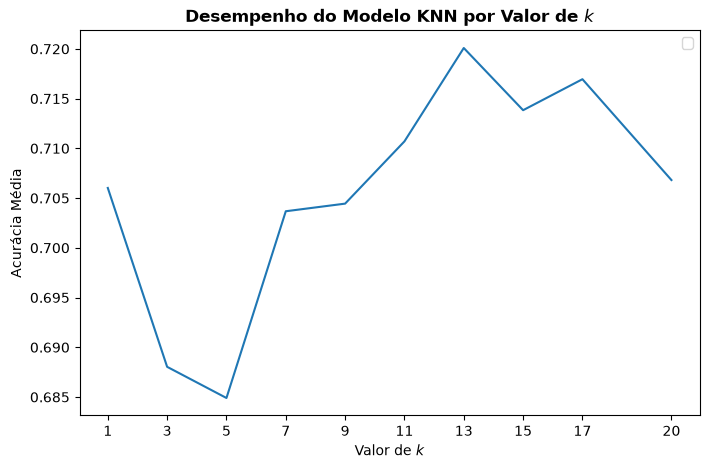

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(k_vals, mean_accuracy)

plt.title('Desempenho do Modelo KNN por Valor de $k$', fontsize=12, fontweight='bold')
plt.xlabel('Valor de $k$', fontsize=10)
plt.ylabel('Acurácia Média', fontsize=10)
plt.xticks(k_vals)
plt.legend()
plt.show();

## 3.5 Avaliação do modelo

In [37]:
from sklearn.metrics import classification_report, confusion_matrix

knn = KNeighborsClassifier(n_neighbors=13)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
classes = knn.classes_

print("--- MATRIZ DE CONFUSÃO ---")
print(cm)

print("--- RELATÓRIO DE CLASSIFICAÇÃO ---")
print(classification_report(y_test, y_pred, target_names=[str(c) for c in classes], zero_division=0))

--- MATRIZ DE CONFUSÃO ---
[[  0   4   0]
 [  0 131  36]
 [  0  46 103]]
--- RELATÓRIO DE CLASSIFICAÇÃO ---
              precision    recall  f1-score   support

         bom       0.00      0.00      0.00         4
       médio       0.72      0.78      0.75       167
        ruim       0.74      0.69      0.72       149

    accuracy                           0.73       320
   macro avg       0.49      0.49      0.49       320
weighted avg       0.72      0.73      0.73       320



# Problema 4 – Classificacão de Risco de Crédito Utilizando Árvores de Decisão

## 4.1 Carregando dataset

In [39]:
from sklearn.datasets import fetch_openml

german_credit_data = fetch_openml(name='credit-g', version=1)
german_credit_df = pd.DataFrame(german_credit_data.data, columns=german_credit_data.feature_names)
german_credit_df['credit_risk'] = german_credit_data.target
german_credit_df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,credit_risk
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [40]:
german_credit_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

In [41]:
german_credit_df['credit_risk'].value_counts()/len(german_credit_df['credit_risk'])

credit_risk
good    0.7
bad     0.3
Name: count, dtype: float64

Como uma proporção de 70% das classes para a variável `credit_risk` estão avaliadas como "bom", um modelo preguiçoso é capaz de obter 70% de acurácia sem aprender nada. Mas não conseguiria predizer nem um dos casos classificados como "ruim".

## 4.2 Codificação das variáveis categóricos

In [42]:
german_credit_df_encoded = pd.get_dummies(german_credit_df.drop('credit_risk', axis=1), drop_first=True)
german_credit_df_encoded['credit_risk'] = german_credit_df['credit_risk'].apply(lambda x: 0 if x == 'good' else 1)
german_credit_df_encoded.head()

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents,checking_status_<0,checking_status_>=200,checking_status_no checking,...,other_payment_plans_none,other_payment_plans_stores,housing_own,housing_rent,job_unemp/unskilled non res,job_unskilled resident,job_skilled,own_telephone_yes,foreign_worker_yes,credit_risk
0,6,1169,4,4,67,2,1,True,False,False,...,True,False,True,False,False,False,True,True,True,0
1,48,5951,2,2,22,1,1,False,False,False,...,True,False,True,False,False,False,True,False,True,1
2,12,2096,2,3,49,1,2,False,False,True,...,True,False,True,False,False,True,False,False,True,0
3,42,7882,2,4,45,1,2,True,False,False,...,True,False,False,False,False,False,True,False,True,0
4,24,4870,3,4,53,2,2,True,False,False,...,True,False,False,False,False,False,True,False,True,1


In [43]:
german_credit_df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 49 columns):
 #   Column                                         Non-Null Count  Dtype   
---  ------                                         --------------  -----   
 0   duration                                       1000 non-null   int64   
 1   credit_amount                                  1000 non-null   int64   
 2   installment_commitment                         1000 non-null   int64   
 3   residence_since                                1000 non-null   int64   
 4   age                                            1000 non-null   int64   
 5   existing_credits                               1000 non-null   int64   
 6   num_dependents                                 1000 non-null   int64   
 7   checking_status_<0                             1000 non-null   bool    
 8   checking_status_>=200                          1000 non-null   bool    
 9   checking_status_no checking                    1000 n

A normalização (ou padronização) dos atributos não é necessária para árvores de decisão por ser uma algorinto invariante a escala monotônica. Além disso, não combina somas ponderadas de atributos diferentes em uma mesma equação de distância.

## 4.3 Divisão dos dados em treino e teste

In [44]:
X = german_credit_df_encoded.drop('credit_risk', axis = 1)
y = german_credit_df_encoded['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

Treino: 800 amostras
Teste:  200 amostras


## 4.4 Treinamento do modelo



In [45]:
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

depth_vals = [2, 3, 5, 7, 10, None]

train_accuracies = []
test_accuracies = []

for val in depth_vals:
    clf = DecisionTreeClassifier(max_depth=val, random_state=7)
    scores = cross_validate(clf, X_train, y_train, cv=5, scoring='accuracy', return_train_score=True)

    train_accuracies.append(np.mean(scores['train_score']))
    test_accuracies.append(np.mean(scores['test_score']))

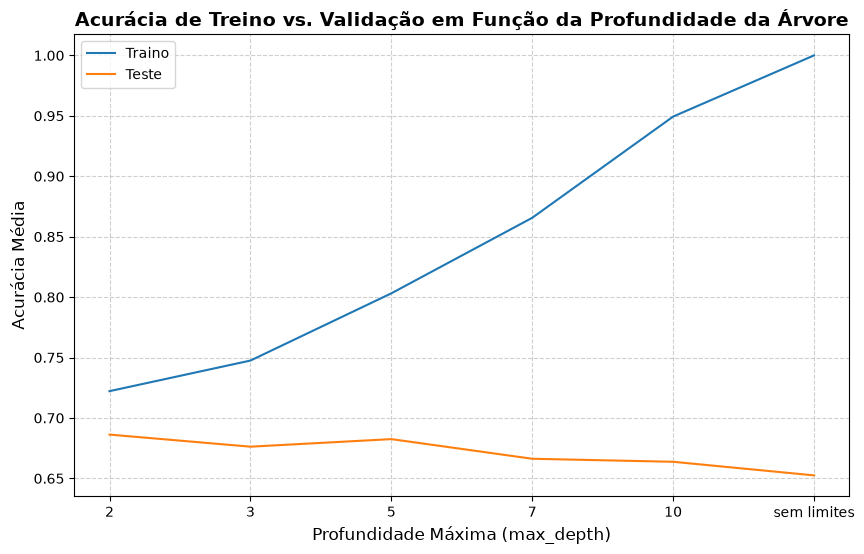

In [46]:
plt.figure(figsize=(10, 6))

depth_labels = ['2', '3', '5', '7', '10', 'sem limites']
plt.plot(depth_labels, train_accuracies, label='Traino')
plt.plot(depth_labels, test_accuracies,label='Teste')

plt.xlabel('Profundidade Máxima (max_depth)', fontsize=12)
plt.ylabel('Acurácia Média', fontsize=12)
plt.title('Acurácia de Treino vs. Validação em Função da Profundidade da Árvore', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

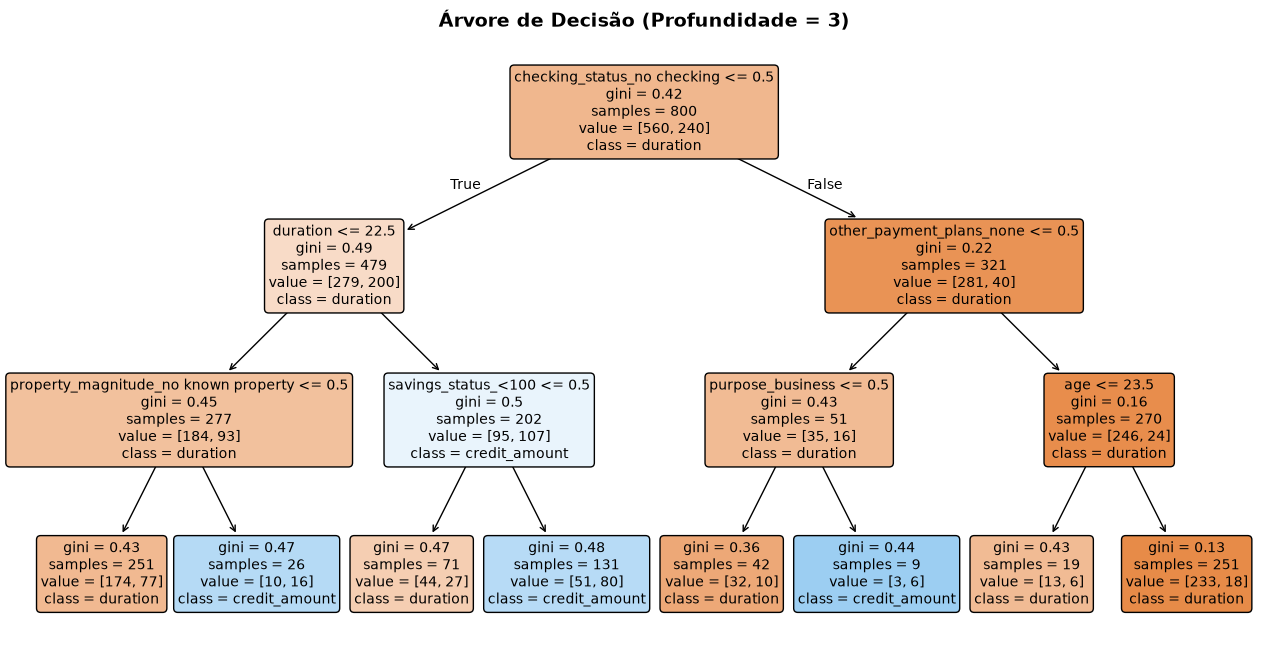

In [47]:
from sklearn.tree import plot_tree

clf = DecisionTreeClassifier(max_depth=3, random_state=7)
clf.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(
    clf,
    feature_names=X_train.columns,
    class_names=X_test.columns,
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10
)
plt.title(f"Árvore de Decisão (Profundidade = 3)", fontsize=14, fontweight='bold')
plt.show()

In [48]:
from sklearn.tree import export_text

tree_rules = export_text(clf, feature_names=list(X_train.columns), class_names=['Bom Risco (0)', 'Mau Risco (1)'])
print(tree_rules)

|--- checking_status_no checking <= 0.50
|   |--- duration <= 22.50
|   |   |--- property_magnitude_no known property <= 0.50
|   |   |   |--- class: Bom Risco (0)
|   |   |--- property_magnitude_no known property >  0.50
|   |   |   |--- class: Mau Risco (1)
|   |--- duration >  22.50
|   |   |--- savings_status_<100 <= 0.50
|   |   |   |--- class: Bom Risco (0)
|   |   |--- savings_status_<100 >  0.50
|   |   |   |--- class: Mau Risco (1)
|--- checking_status_no checking >  0.50
|   |--- other_payment_plans_none <= 0.50
|   |   |--- purpose_business <= 0.50
|   |   |   |--- class: Bom Risco (0)
|   |   |--- purpose_business >  0.50
|   |   |   |--- class: Mau Risco (1)
|   |--- other_payment_plans_none >  0.50
|   |   |--- age <= 23.50
|   |   |   |--- class: Bom Risco (0)
|   |   |--- age >  23.50
|   |   |   |--- class: Bom Risco (0)



## 4.5 Avaliação do modelo

In [49]:
y_pred = clf.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(f'Matriz de Confusão: \n{cm}')

print("\nMétricas por Classe:")
print(classification_report(y_test, y_pred, target_names=['Bom Risco(0)', 'Mau Risco (1)']))

Matriz de Confusão: 
[[122  18]
 [ 34  26]]

Métricas por Classe:
               precision    recall  f1-score   support

 Bom Risco(0)       0.78      0.87      0.82       140
Mau Risco (1)       0.59      0.43      0.50        60

     accuracy                           0.74       200
    macro avg       0.69      0.65      0.66       200
 weighted avg       0.72      0.74      0.73       200

